# 02 · Modelo final: LightGBM con Catastro y texto (envío 02)

Qué hace. Reconstruye, paso a paso, el modelo que obtuvo el segundo lugar de seis equipos en la tabla privada de Kaggle
(error absoluto medio de 150,79 millones). Arma las 162 variables, describe la especificación del LightGBM, resume su
validación, explica los dos ajustes posteriores (el factor 1,08 alrededor de la media del entrenamiento y la corrección por
gemelos de texto) y genera el archivo de envío.

Cómo. El cuaderno no vuelve a entrenar nada por defecto. Ejecuta la parte de datos del flujo final (`cv_clase.py`, que a su
vez usa `pronostico_rapido.py`, `modelo_utils.py` y `validacion_clase.py`), lee las predicciones guardadas en `stores/` y
comprueba que el archivo que produce es idéntico, byte por byte, a los envíos 01 y 02 archivados en
`submissions/kaggle_subidos/`. Con `RECALCULAR = True` reentrena el modelo final con 5 semillas y escribe solo en
`stores/recalculo/`.

Para qué. Es el cuaderno que responde la Etapa 4 del enunciado (especificación, hiperparámetros y predictores del mejor
modelo) y que deja reproducible el envío que cuenta para la clasificación.

Conceptos de clase que usa:

| Concepto | Dónde se enseña | Sección del cuaderno |
|---|---|---|
| Modelo hedónico de Rosen: el precio como función de las características | Enunciado, sección 3 | 1 |
| Variables de OpenStreetMap (distancia al parque, restaurantes a 2 km), CRS EPSG:9377 | Lectura Datos espaciales; Lecture 14, diap. 10 y 11 | 1.2 |
| Bolsa de palabras, TF-IDF y regresión penalizada sobre el texto | Lecture 15, diap. 14 a 18; Gentzkow, Kelly y Taddy (2019), ec. 2, p. 543 | 1.5 |
| Los árboles no extrapolan fuera del rango del entrenamiento | Lecture 14, cuaderno 01_SpatialData | 1.4 |
| Boosting: suma de árboles pequeños ajustados a los residuos | ISLR, cap. 8.2.3 (fuera de la carpeta de lecturas) | 2 |
| Parada temprana con una partición de validación | Lecture 12, diap. 23 y 24 | 2 |
| Validación cruzada espacial, partición interna con la misma lógica | Lectura Validación cruzada espacial (Rojas y Sarmiento-Barbieri, 2026); Lecture 14, diap. 16 a 31 | 3 |

Orden de ejecución: después de `00` y `01`. Tiempo: menos de 1 minuto con `RECALCULAR = False`.

## 0. Configuración

In [1]:
# Bandera de recálculo. False: solo lee resultados guardados. True: reentrena el LightGBM final (5 semillas, unos minutos)
# y escribe en stores/recalculo/, nunca sobre los archivos que usan las presentaciones.
RECALCULAR = False

import warnings
warnings.filterwarnings("ignore")
import hashlib
import io
import time

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import cuadernos_utils as cu
from cuadernos_utils import coma, tabla_coma

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 90)
COLOR_TRAIN, COLOR_TEST = "#4C72B0", "#DD8452"
t0 = time.time()


def guardar_figura(fig, nombre):
    # Figuras con el prefijo del cuaderno en views/ (no las usa ninguna presentación)
    fig.savefig(cu.VIEWS / f"02_{nombre}.png")

## 1. La base: 162 variables por aviso

`cargar_flujo` ejecuta el mismo código que produjo los envíos (sin validar ni entrenar). Construye la base de 48.930 avisos
(38.644 de entrenamiento y 10.286 de prueba), une Earth Engine por coordenada, el texto por identificador y las localidades
por ubicación, calcula las variables de OpenStreetMap en metros (EPSG:9377) y arma los pliegues de validación.

In [2]:
F = cu.cargar_flujo("clusters")                     # base, variables y pliegues del flujo final (unos 30 segundos)
g, y, idx_tr, idx_te = F.g, F.y, F.idx_tr, F.idx_te
print(f"Avisos: {len(g):,} | entrenamiento {len(idx_tr):,} | prueba {len(idx_te):,}".replace(",", "."))
print(f"Media del precio en entrenamiento: {coma(y[idx_tr].mean())} millones")

[  0.1 min] Variables: estructurales 15, externas 24 + adicionales 26, texto 83, BETO PCA 32, BETO ajustado 1


[  0.2 min] AUC adversarial (composición): 0.922


[  0.2 min] V3: 20,144 avisos en 80 bloques de 1 km


[  0.2 min] Variables: sin Catastro 150 | con Catastro 161 (+ puntaje de texto)


[  0.2 min] clusters: 10 pliegues | validación 38,644 | entrenamiento medio 34,780 | parada interna media 4,472


[  0.2 min] Chapinero (imitando el taller): 1 pliegues | validación 307 | entrenamiento medio 38,337 | parada interna media 2,074


[  0.2 min] Fin


Avisos: 48.930 | entrenamiento 38.644 | prueba 10.286
Media del precio en entrenamiento: 654,5 millones


### 1.1 Los bloques de variables

Siguiendo la idea hedónica del enunciado, $P_i = f(c_{i1}, \dots, c_{in}) + u_i$, cada aviso se describe con características
de la vivienda, de su entorno y de su texto. La teoría dice qué características importan; la forma de $f$ la aprende el
modelo. Los 161 predictores fijos más el puntaje de texto dan las 162 columnas del modelo.

In [3]:
# Bloques tal como los define pronostico_rapido.py y cv_clase.py
OSM_BASE = [c for c in F.EXTERNAS if c.startswith("ln_") and c != "ln_poblacion_100m"]
GEE_VARS = [c for c in F.EXTERNAS if c not in OSM_BASE]
BLOQUES = {
    "Vivienda (Kaggle completado con el texto)": (F.ESTRUCTURALES, "Kaggle + cuaderno 01 (sección 9.4)"),
    "OpenStreetMap y distancias a centros": (OSM_BASE, "pronostico_rapido.py (extracto BBBike)"),
    "Google Earth Engine": (GEE_VARS, "stores/gee_features.parquet"),
    "Entorno adicional (OSM y avisos sin precio)": (F.EXTRA, "variables_externas_extra.py"),
    "Catastro de Bogotá (manzana y 300 m)": (F.CATASTRO, "descargar_catastro.py + variables_catastro.py"),
    "Texto (diccionarios, cantidades, LDA, LSA)": (F.TEXTO, "cuaderno 01 (sección 9)"),
    "Coordenadas (km, EPSG:9377)": (F.COORD, "pronostico_rapido.py"),
    "Puntaje de texto (ridge fuera de pliegue)": (["puntaje_texto_ridge"], "pronostico_rapido.py, puntaje_texto()"),
}
NOMBRES = F.COLUMNAS["con"] + ["puntaje_texto_ridge"]
BLOQUE_DE = {v: b for b, (vs, _) in BLOQUES.items() for v in vs}
assert len(NOMBRES) == 162 and set(NOMBRES) == set(BLOQUE_DE)
pd.DataFrame([{"bloque": b, "variables": len(vs), "construidas en": f} for b, (vs, f) in BLOQUES.items()]
             + [{"bloque": "Total", "variables": len(NOMBRES), "construidas en": ""}]).set_index("bloque")

,variables,construidas en
bloque,,
Vivienda (Kaggle completado con el texto),15,Kaggle + cuaderno 01 (sección 9.4)
OpenStreetMap y distancias a centros,18,pronostico_rapido.py (extracto BBBike)
Google Earth Engine,6,stores/gee_features.parquet
Entorno adicional (OSM y avisos sin precio),26,variables_externas_extra.py
Catastro de Bogotá (manzana y 300 m),11,descargar_catastro.py + variables_catastro.py
"Texto (diccionarios, cantidades, LDA, LSA)",83,cuaderno 01 (sección 9)
"Coordenadas (km, EPSG:9377)",2,pronostico_rapido.py
Puntaje de texto (ridge fuera de pliegue),1,"pronostico_rapido.py, puntaje_texto()"
Total,162,


### 1.2 El puntaje de texto: regresión de texto fuera de pliegue

Es la única variable que usa el precio, así que se calcula sin fuga. Para cada conjunto de entrenamiento $\mathcal{T}$ se
ajusta un ridge del logaritmo del precio sobre la matriz TF-IDF $\mathbf{X}$ del cuaderno 01 (unigramas y bigramas,
44.888 términos):

$$\hat{\boldsymbol\beta} = \arg\min_{a, \boldsymbol\beta} \sum_{i \in \mathcal{T}} \big(\ln P_i - a - \mathbf{x}_i^{\top}\boldsymbol\beta\big)^2 + \alpha \lVert \boldsymbol\beta \rVert_2^2, \qquad \alpha = 1$$

Es la regresión de texto de Gentzkow, Kelly y Taddy (2019, ec. 2) con penalidad L2. En las filas de entrenamiento el
puntaje sale de un `GroupKFold` de 5 grupos por texto duplicado (un aviso nunca se predice con su copia); en las filas de
validación o de prueba sale del ajuste con todo $\mathcal{T}$. En la validación cruzada se recalcula dentro de cada pliegue.

In [4]:
punt = cu.puntaje_guardado(F, "final")             # stores/cache_puntajes_texto/ridge_final.npy
X = np.c_[g[F.COLUMNAS["con"]].to_numpy(float), punt]
g["puntaje_texto_ridge"] = punt
rho = np.corrcoef(punt[idx_tr], F.lp[idx_tr])[0, 1]
print(f"Correlación entre el puntaje fuera de pliegue y ln(precio) en entrenamiento: {coma(rho, 3)}")
print(f"Puntaje en millones (exp): mediana entrenamiento {coma(np.exp(np.median(punt[idx_tr])), 0)}, "
      f"mediana prueba {coma(np.exp(np.median(punt[idx_te])), 0)}")

Correlación entre el puntaje fuera de pliegue y ln(precio) en entrenamiento: 0,812
Puntaje en millones (exp): mediana entrenamiento 581, mediana prueba 678


### 1.3 Diccionario de las 162 columnas

Para cada variable: bloque, porcentaje de faltantes, mediana en entrenamiento y en prueba, y la diferencia estandarizada
$d_v = (\bar v_{\text{prueba}} - \bar v_{\text{entrenamiento}}) / s_{v,\text{entrenamiento}}$, que indica cuánto se aleja
Chapinero de lo que el modelo vio. LightGBM maneja los faltantes de forma nativa: en cada partición aprende hacia qué lado
mandarlos.

In [5]:
Xtr, Xte = X[idx_tr], X[idx_te]
dicc = pd.DataFrame({
    "bloque": [BLOQUE_DE[v] for v in NOMBRES],
    "% faltante entrenamiento": 100 * np.isnan(Xtr).mean(0),
    "% faltante prueba": 100 * np.isnan(Xte).mean(0),
    "mediana entrenamiento": np.nanmedian(Xtr, 0),
    "mediana prueba": np.nanmedian(Xte, 0),
    "d (prueba menos entrenamiento)": (np.nanmean(Xte, 0) - np.nanmean(Xtr, 0)) / np.nanstd(Xtr, 0),
}, index=pd.Index(NOMBRES, name="variable"))
print("Variables con |d| > 1 (Chapinero muy distinto del entrenamiento):",
      ", ".join(dicc.index[dicc["d (prueba menos entrenamiento)"].abs() > 1]))
tabla_coma(dicc, 2)

Variables con |d| > 1 (Chapinero muy distinto del entrenamiento): ln_n_restaurantes_2km, ln_dist_p93_m, ln_dist_zonat_m, elevacion_m, pendiente_grados, ln_n_oficina_1000m, ln_n_hotel_1000m, ln_n_embajada_1000m, ln_dist_embajada_m, ln_n_restaurante_1km, ln_n_bar_cafe_1km, ln_dist_area_protegida_m, ln_vref_manzana, ln_vref_300m, ln_avaluo_ph_300m, pisos_300m, prop_estrato6_300m


,bloque,% faltante entrenamiento,% faltante prueba,mediana entrenamiento,mediana prueba,d (prueba menos entrenamiento)
variable,,,,,,
es_apartamento,Vivienda (Kaggle completado con el texto),"0,00","0,00","1,00","1,00","0,51"
bedrooms,Vivienda (Kaggle completado con el texto),"0,00","0,00","3,00","2,00","-0,50"
rooms,Vivienda (Kaggle completado con el texto),"47,25","44,55","3,00","2,00","-0,47"
banos_imp,Vivienda (Kaggle completado con el texto),"14,82","13,54","3,00","3,00","-0,14"
area_imp,Vivienda (Kaggle completado con el texto),"46,70","43,30","112,00","119,00","-0,12"
log_area,Vivienda (Kaggle completado con el texto),"46,70","43,30","4,72","4,78","-0,09"
parqueaderos_imp,Vivienda (Kaggle completado con el texto),"0,00","0,00","1,00","1,00","0,08"
piso_texto,Vivienda (Kaggle completado con el texto),"70,52","74,08","2,00","3,00","0,13"
estrato_texto,Vivienda (Kaggle completado con el texto),"92,62","94,59","4,00","5,00","0,73"


### 1.4 Catastro: la variable que más se sale del rango

El valor de referencia del suelo por manzana (Catastro, año del aviso) resume en un número lo que hace caro a Chapinero.
Pero la prueba está casi toda por encima de lo que el entrenamiento cubre. Un árbol asigna a cualquier valor por encima del
último corte la misma hoja: no extrapola (Lecture 14, cuaderno 01_SpatialData). Ese es el origen del sesgo hacia abajo que
se corrige en parte con el factor 1,08 (sección 4).

In [6]:
v = "ln_vref_300m"
lo, hi = np.nanpercentile(g[v].values[idx_tr], [1, 99])
val = g[v].values[idx_te]
print(f"Valor del suelo a 300 m, percentil 99 del entrenamiento: {coma(np.exp(hi) / 1e6, 1)} millones por m²")
print(f"Prueba por encima del p99: {coma(100 * np.mean(val > hi))} % | fuera del rango p1 a p99: "
      f"{coma(100 * np.mean((val < lo) | (val > hi)))} %")
print(f"Estrato de la manzana, mediana: entrenamiento {coma(np.nanmedian(g['estrato_manzana'].values[idx_tr]), 0)}, "
      f"prueba {coma(np.nanmedian(g['estrato_manzana'].values[idx_te]), 0)}")

Valor del suelo a 300 m, percentil 99 del entrenamiento: 5,9 millones por m²
Prueba por encima del p99: 56,8 % | fuera del rango p1 a p99: 59,5 %
Estrato de la manzana, mediana: entrenamiento 4, prueba 6


### 1.5 Mapas de cuatro variables en la coordenada exacta de cada aviso

Un punto por coordenada (si varios avisos comparten coordenada, el punto toma su promedio), entrenamiento y prueba juntos.
Contorno negro: Chapinero. Escala recortada entre los percentiles 2 y 98.

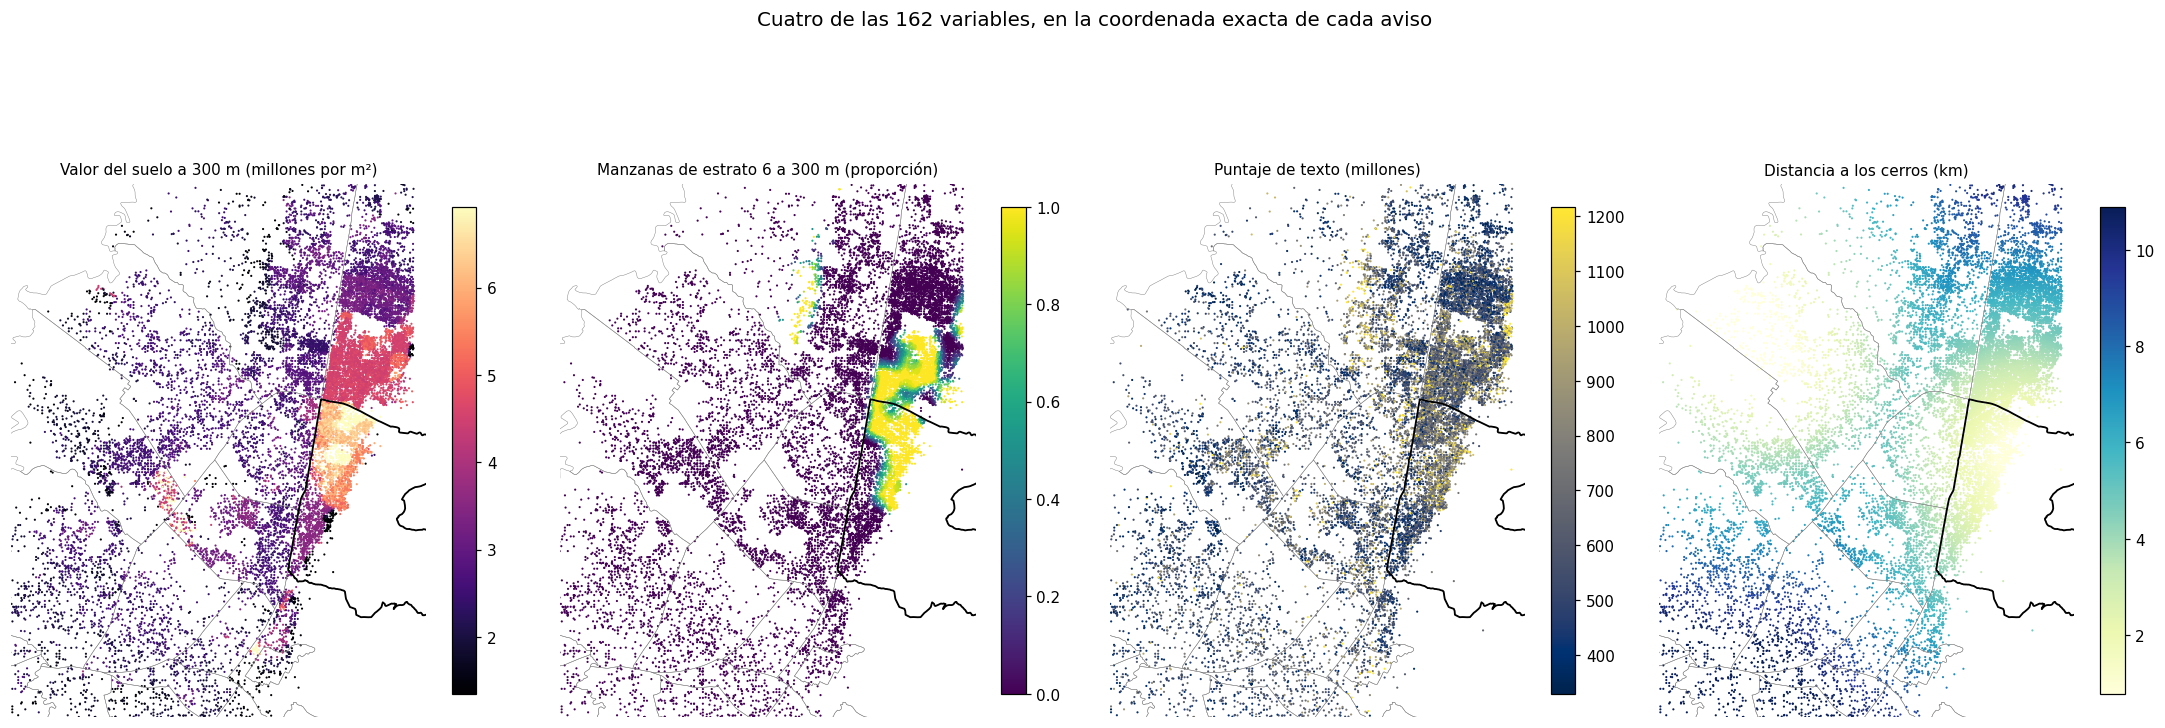

In [7]:
loc = gpd.read_file(cu.STORES / "localidades_bogota.geojson").to_crs("EPSG:9377")
chap = loc[loc["localidad"] == "Chapinero"]
g["vref_300m_mill"] = np.exp(g["ln_vref_300m"]) / 1e6
g["puntaje_mill"] = np.exp(g["puntaje_texto_ridge"])
g["dist_cerros_km"] = np.expm1(g["ln_dist_area_protegida_m"]) / 1000
EXT = np.r_[np.percentile(g["x"], 0.5) - 500, np.percentile(g["y"], 0.5) - 500,
            np.percentile(g["x"], 99.5) + 500, np.percentile(g["y"], 99.5) + 500]


def mapa_puntos(ax, var, titulo, cmap):
    u = g.groupby(["x", "y"], as_index=False)[var].mean().dropna().sample(frac=1, random_state=2026)
    sc = ax.scatter(u["x"], u["y"], c=u[var], s=2, cmap=cmap, linewidths=0,
                    vmin=u[var].quantile(.02), vmax=u[var].quantile(.98))
    loc.boundary.plot(ax=ax, color="grey", lw=0.3)
    chap.boundary.plot(ax=ax, color="black", lw=1.2)
    ax.set_xlim(EXT[0], EXT[2]); ax.set_ylim(EXT[1], EXT[3]); ax.set_axis_off()
    plt.colorbar(sc, ax=ax, shrink=0.6)
    ax.set_title(titulo, fontsize=10)


fig, axes = plt.subplots(1, 4, figsize=(20, 8))
for ax, (v_, t_, c_) in zip(axes, [("vref_300m_mill", "Valor del suelo a 300 m (millones por m²)", "magma"),
                                   ("prop_estrato6_300m", "Manzanas de estrato 6 a 300 m (proporción)", "viridis"),
                                   ("puntaje_mill", "Puntaje de texto (millones)", "cividis"),
                                   ("dist_cerros_km", "Distancia a los cerros (km)", "YlGnBu")]):
    mapa_puntos(ax, v_, t_, c_)
fig.suptitle("Cuatro de las 162 variables, en la coordenada exacta de cada aviso", fontsize=13)
fig.tight_layout()
guardar_figura(fig, "mapas_variables")
plt.show()

## 2. Especificación del modelo

Gradient boosting con árboles (LightGBM, objetivo L2, precio en millones en niveles). Con pérdida cuadrática, cada árbol
$T_m$ se ajusta a los residuos del modelo acumulado y se suma con una tasa de aprendizaje $\eta$:

$$\hat f_0(\mathbf{x}) = \bar y, \qquad r_{im} = y_i - \hat f_{m-1}(\mathbf{x}_i), \qquad
\hat f_m(\mathbf{x}) = \hat f_{m-1}(\mathbf{x}) + \eta\, T_m(\mathbf{x}; r_{\cdot m}), \qquad m = 1, \dots, M$$

LightGBM crece cada árbol por hojas (elige la hoja cuya división reduce más la pérdida) y evalúa cada corte con la ganancia

$$\text{ganancia} = \frac{1}{2}\left[\frac{G_L^2}{n_L + \lambda} + \frac{G_R^2}{n_R + \lambda} - \frac{(G_L + G_R)^2}{n_L + n_R + \lambda}\right],
\qquad G = \sum_{i \in \text{hoja}} r_{im}$$

con $\lambda$ la penalidad L2 de las hojas. El objetivo es la media condicional (L2) y no la mediana (L1): Chapinero es más
caro que el entrenamiento y la media subestima menos (bitácora, paso 11).

El número de árboles $M$ se elige con parada temprana (Lecture 12, diap. 23 y 24): se separa el 20 % de las celdas de 2 km
del entrenamiento como validación interna (`modelo_utils.bloques_internos`), se para cuando el error cuadrático interno no
mejora en 100 árboles y se reentrena con todo el entrenamiento usando ese $M$. El modelo final promedia 5 semillas
(2026 a 2030). Los demás hiperparámetros quedaron fijos (se tomaron de una rejilla previa del equipo con validación
espacial); solo $M$ sale de los datos.

In [8]:
hiper = pd.DataFrame([
    ("objective", "l2", "pérdida cuadrática: estima la media condicional"),
    ("learning_rate", "0,05", "tasa de aprendizaje η"),
    ("num_leaves", "63", "hojas máximas por árbol"),
    ("min_child_samples", "20", "avisos mínimos por hoja"),
    ("subsample / subsample_freq", "0,8 / 1", "80 % de los avisos en cada árbol"),
    ("colsample_bytree", "0,7", "70 % de las variables en cada árbol"),
    ("reg_lambda", "1,0", "penalidad L2 λ de los valores de las hojas"),
    ("n_estimators", "parada temprana", "hasta 5.000; paciencia de 100 árboles"),
    ("semillas", "5", "promedio de 2026 a 2030"),
], columns=["hiperparámetro", "valor", "significado"]).set_index("hiperparámetro")
hiper

,valor,significado
hiperparámetro,,
objective,l2,pérdida cuadrática: estima la media condicional
learning_rate,"0,05",tasa de aprendizaje η
num_leaves,63,hojas máximas por árbol
min_child_samples,20,avisos mínimos por hoja
subsample / subsample_freq,"0,8 / 1",80 % de los avisos en cada árbol
colsample_bytree,"0,7",70 % de las variables en cada árbol
reg_lambda,"1,0",penalidad L2 λ de los valores de las hojas
n_estimators,parada temprana,hasta 5.000; paciencia de 100 árboles
semillas,5,promedio de 2026 a 2030


Ajuste interno: 30.849 avisos | parada: 7.795 avisos
Árboles elegidos por parada temprana con la semilla 2026: 252


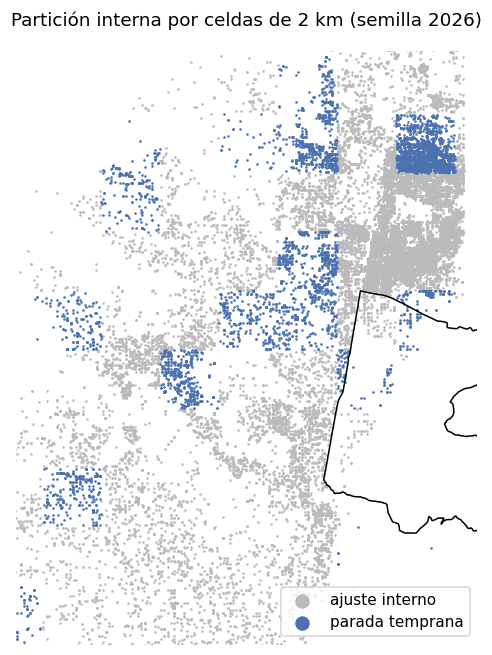

In [9]:
# Partición interna de la parada temprana para la semilla 2026 (celdas de 2 km; ~20 % de las celdas para parar)
i_in, i_iv = F.mu.bloques_internos(F.xs[idx_tr], F.ys[idx_tr], semilla=F.SEMILLA)
print(f"Ajuste interno: {len(i_in):,} avisos | parada: {len(i_iv):,} avisos".replace(",", "."))
# Número de árboles de la semilla 2026, guardado al calcular los valores SHAP de las presentaciones
arboles = pd.read_csv(cu.DATOS_PPT / "hiperparametros_lightgbm.csv").set_index("parametro").loc["n_estimators", "valor"]
print(f"Árboles elegidos por parada temprana con la semilla 2026: {arboles}")
fig, ax = plt.subplots(figsize=(6, 7))
ax.scatter(F.xs[idx_tr][i_in], F.ys[idx_tr][i_in], s=0.5, color="#BBBBBB", label="ajuste interno")
ax.scatter(F.xs[idx_tr][i_iv], F.ys[idx_tr][i_iv], s=0.5, color=COLOR_TRAIN, label="parada temprana")
chap.boundary.plot(ax=ax, color="black", lw=1)
ax.set_xlim(EXT[0], EXT[2]); ax.set_ylim(EXT[1], EXT[3]); ax.set_axis_off()
ax.legend(markerscale=12, loc="lower right")
ax.set_title("Partición interna por celdas de 2 km (semilla 2026)")
guardar_figura(fig, "particion_interna")
plt.show()

## 3. Validación del modelo final

La comparación completa de esquemas y familias está en el cuaderno 03. Aquí se resume la del modelo elegido. En cada
pliegue se vuelve a calcular el puntaje de texto solo con el entrenamiento del pliegue y la parada temprana usa una
partición interna con la misma lógica del esquema externo (lectura Validación cruzada espacial, función `fun_fit_net`).

Para cada esquema se reportan, sobre las predicciones reunidas de todos los pliegues,

$$\text{MAE} = \frac{1}{n}\sum_i |\hat y_i - y_i|, \qquad \text{RMSE} = \sqrt{\frac{1}{n}\sum_i (\hat y_i - y_i)^2}, \qquad
\text{sesgo} = \frac{1}{n}\sum_i (\hat y_i - y_i)$$

Un sesgo negativo significa que el modelo predice por debajo del precio. Chapinero fuera entrena con todo el entrenamiento
menos los 307 avisos de Chapinero y los predice: es el análogo del ejercicio de la clase "imitando el taller".

In [10]:
res = pd.read_csv(cu.STORES / "cv_clase_res_lightgbm_con.csv")
rk = pd.read_csv(cu.STORES / "rk_knndm_res_lightgbm_con.csv").set_index("variante").loc["sin kriging"]
nombres_esq = {"aleatoria": "CV aleatoria (5 pliegues)", "bloques": "Bloques de 2 km", "bloques_buffer": "Bloques de 2 km con buffer de 300 m",
               "clusters": "Clústeres k-means (10)", "Chapinero (imitando el taller)": "Chapinero fuera (307 avisos)"}
val = res.assign(esquema=res["esquema"].map(nombres_esq)).set_index("esquema")[["n", "MAE", "RMSE", "Sesgo"]]
val.loc["kNNDM (q = 1.600)"] = [len(idx_tr), rk["MAE kNNDM"], rk["RMSE kNNDM"], rk["Sesgo"]]
reg = pd.read_csv(cu.SUBMISSIONS / "kaggle_subidos" / "registro_envios.csv")
privado_01 = float(reg.loc[reg["n"].astype(str) == "1", "puntaje_privado_80"].iloc[0])
val["Kaggle privado (envío 01) menos validación"] = privado_01 - val["MAE"]
print(f"Envío 01 (este modelo sin el factor 1,08): tabla pública 153,50, tabla privada {coma(privado_01, 2)}")
val["n"] = val["n"].astype(int)
tabla_coma(val).assign(n=val["n"].map(lambda v: coma(v, 0)))

Envío 01 (este modelo sin el factor 1,08): tabla pública 153,50, tabla privada 152,43


,n,MAE,RMSE,Sesgo,Kaggle privado (envío 01) menos validación
esquema,,,,,
CV aleatoria (5 pliegues),38.644,"78,8","128,7","2,3","73,6"
Bloques de 2 km,38.644,"119,1","171,3","1,5","33,4"
Bloques de 2 km con buffer de 300 m,38.644,"123,1","175,0","3,3","29,3"
Clústeres k-means (10),38.644,"125,0","175,8","5,4","27,4"
Chapinero fuera (307 avisos),307,"143,8","197,8","-52,3","8,7"
kNNDM (q = 1.600),38.644,"111,7","162,2","-0,2","40,8"


Lectura. La CV aleatoria promete un error cercano a la mitad del de Kaggle: valida avisos cuya copia o cuyo vecino de la
misma coordenada está en el entrenamiento. A medida que la validación se aleja en el espacio, el error sube y se acerca al de
Kaggle. Chapinero fuera es la que más se acerca (queda 9,7 millones por debajo de la tabla pública y 8,7 por debajo de la
privada) y la única que muestra el sesgo hacia abajo que tiene el modelo en Chapinero. Por eso se usó para decidir.

## 4. El ajuste final ×1,08

Todas las validaciones espaciales muestran el mismo patrón: el modelo comprime las predicciones hacia la media. En Chapinero
fuera subestima en todos los quintiles de la predicción, y en kNNDM subestima en más de 200 millones los avisos de más de
1.000 millones. Como Chapinero es más caro que el entrenamiento, se estira la predicción alrededor de la media del
entrenamiento, $\bar y = 654$ millones:

$$\tilde y_i = \bar y + b\,(\hat y_i - \bar y), \qquad b = 1{,}08$$

El valor 1,08 viene del análisis de diseño (bitácora, paso M3: estirar entre 1,05 y 1,10 bajaba el error en Chapinero) y se
probó en Chapinero fuera y en clústeres antes del envío. Advertencia: el 140,8 de Chapinero fuera con ×1,08 se mide en la
misma validación que ayudó a elegir el factor, así que es optimista. Kaggle lo confirmó después: el envío 02 (con ×1,08)
quedó 1,6 millones mejor que el 01 en la tabla privada.

Pendiente de la recta real sobre predicho en Chapinero fuera: 1,09 (1 sería sin compresión)


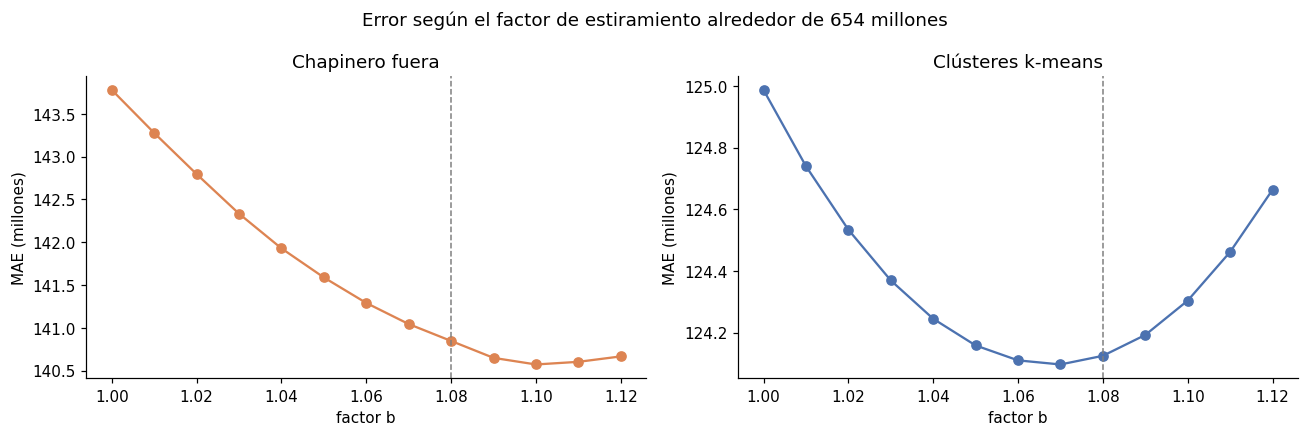

,MAE Chapinero fuera,sesgo Chapinero fuera,MAE clústeres
b,,,
"1,00","143,78","-52,32","124,99"
"1,01","143,28","-50,91","124,74"
"1,02","142,80","-49,50","124,53"
"1,03","142,33","-48,10","124,37"
"1,04","141,93","-46,69","124,24"
"1,05","141,59","-45,28","124,16"
"1,06","141,29","-43,87","124,11"
"1,07","141,04","-42,46","124,10"
"1,08","140,85","-41,05","124,12"


In [11]:
oof = pd.read_parquet(cu.STORES / "cv_clase_oof_lightgbm_con.parquet")
ch = oof[oof["esquema"].str.startswith("Chapinero")]
cl = oof[oof["esquema"] == "clusters"]
filas = []
for b in np.round(np.arange(1.00, 1.125, 0.01), 2):
    f = lambda o: cu.CENTRO + b * (o["pred"] - cu.CENTRO)
    filas.append({"b": b, "MAE Chapinero fuera": np.abs(f(ch) - ch["real"]).mean(), "sesgo Chapinero fuera": (f(ch) - ch["real"]).mean(),
                  "MAE clústeres": np.abs(f(cl) - cl["real"]).mean()})
rejilla_b = pd.DataFrame(filas).set_index("b")
# Pendiente de la recta precio real ~ predicción en Chapinero fuera: > 1 indica compresión
pend = np.polyfit(ch["pred"], ch["real"], 1)[0]
print(f"Pendiente de la recta real sobre predicho en Chapinero fuera: {coma(pend, 2)} (1 sería sin compresión)")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rejilla_b.index, rejilla_b["MAE Chapinero fuera"], "o-", color=COLOR_TEST)
ax[0].set(title="Chapinero fuera", xlabel="factor b", ylabel="MAE (millones)")
ax[1].plot(rejilla_b.index, rejilla_b["MAE clústeres"], "o-", color=COLOR_TRAIN)
ax[1].set(title="Clústeres k-means", xlabel="factor b", ylabel="MAE (millones)")
for a in ax:
    a.axvline(1.08, color="grey", ls="--", lw=1)
fig.suptitle("Error según el factor de estiramiento alrededor de 654 millones")
fig.tight_layout()
guardar_figura(fig, "factor_estiramiento")
plt.show()
tabla_coma(rejilla_b.reset_index(), 2).set_index("b")

El mínimo en Chapinero fuera está cerca de 1,10 y en clústeres cerca de 1,07; 1,08 queda en la zona plana de las dos
curvas. En clústeres, que cubre toda Bogotá, el estiramiento casi no cambia el error: en el resto de la ciudad el modelo no
estaba comprimido (cuaderno 04, calibración por decil).

## 5. Corrección por gemelos de texto

Un mismo inmueble se publica varias veces con el mismo texto. El cuaderno 01 asigna a cada aviso una huella (`grupo_texto`,
MD5 del texto normalizado). Si un aviso de prueba tiene un gemelo en el entrenamiento, su precio es información directa del
mismo inmueble. La regla, fijada de antemano (bitácora, paso M4), combina la predicción con la mediana del precio de los
gemelos $\tilde p_i$:

$$\hat y_i^{\text{final}} = 0{,}3\, \tilde y_i + 0{,}7\, \tilde p_i \quad \text{si el aviso tiene gemelo}, \qquad
\hat y_i^{\text{final}} = \tilde y_i \quad \text{si no}$$

Se aplica después del ×1,08. Afecta a 78 avisos de prueba (0,8 %).

In [12]:
gem = pd.Series(y[idx_tr], index=F.grupo[idx_tr]).groupby(level=0).median()      # mediana del precio por texto
precio_gemelo = pd.Series(F.grupo[idx_te]).map(gem).to_numpy()
tiene = np.isfinite(precio_gemelo)
print(f"Avisos de prueba con gemelo de texto en entrenamiento: {tiene.sum()} ({coma(100 * tiene.mean(), 2)} %)")

# Comprobación a posteriori (no se usó para fijar 0,3 y 0,7): en la CV por clústeres, avisos de validación con un gemelo
# en el entrenamiento de su pliegue.
pl = {n: v for n, v in F.PLIEGUES_CLASE.items() if v[0] == "clusters"}
filas = []
for n, (e, a, b, _) in pl.items():
    gm = pd.Series(y[a], index=F.grupo[a]).groupby(level=0).median()
    pg = pd.Series(F.grupo[b]).map(gm).to_numpy()
    o = cl[cl["pliegue"] == n].set_index("idx").loc[b]
    m = np.isfinite(pg)
    filas.append(pd.DataFrame({"pred": o["pred"].values[m], "real": o["real"].values[m], "gemelo": pg[m]}))
gv = pd.concat(filas)
comp = pd.DataFrame({"peso del gemelo": np.round(np.arange(0, 1.01, 0.1), 1)})
comp["MAE"] = [np.abs((1 - w) * gv["pred"] + w * gv["gemelo"] - gv["real"]).mean() for w in comp["peso del gemelo"]]
print(f"Avisos de validación (clústeres) con gemelo en su entrenamiento: {len(gv):,}".replace(",", "."))
comp["peso del gemelo"] = comp["peso del gemelo"].map(lambda v: coma(v, 1))
tabla_coma(comp).set_index("peso del gemelo")

Avisos de prueba con gemelo de texto en entrenamiento: 78 (0,76 %)
Avisos de validación (clústeres) con gemelo en su entrenamiento: 89


,MAE
peso del gemelo,
"0,0","167,4"
"0,1","156,8"
"0,2","146,5"
"0,3","138,5"
"0,4","132,4"
"0,5","127,8"
"0,6","123,4"
"0,7","119,1"
"0,8","115,3"


En la validación por clústeres hay 89 avisos con un gemelo en el entrenamiento de su pliegue. Darle peso al gemelo reduce
mucho su error: con 0,7 el MAE de esos avisos baja de 167,4 a 119,1 millones, y el mínimo está en 0,9 (112,8). La regla
0,3 y 0,7 queda del lado prudente. Es una comprobación hecha después del envío, sobre otros avisos.

## 6. Generación del envío y comprobación con los archivos subidos a Kaggle

Con `RECALCULAR = False` se leen las predicciones del modelo final (promedio de 5 semillas) guardadas por
`cv_clase.py` en modo final. Se aplican el ×1,08 y los gemelos, se arma el archivo con el formato de
`submission_template.csv` (precio en pesos, redondeado) y se compara su huella SHA-256 con la del registro de envíos.

In [13]:
if RECALCULAR:
    # Mismo ajuste que MODO=final de cv_clase.py: 5 semillas en paralelo (5 procesos de 3 hilos)
    from joblib import Parallel, delayed
    preds = Parallel(n_jobs=5)(delayed(F.mu.ajustar_predecir)("lightgbm", X, y, F.xs, F.ys, F.lpm2, F.lp, F.grupo, None,
                                                               idx_tr, idx_te, False, False, {}, F.SEMILLA + s)
                               for s in range(5))
    L = np.mean(preds, axis=0)
    np.save(cu.ruta_salida("final_pred_lightgbm_con.npy", RECALCULAR), L)
else:
    L = np.load(cu.STORES / "final_pred_lightgbm_con.npy")
print(f"Predicción del LightGBM (sin ajustes): media {coma(L.mean())}, mediana {coma(np.median(L))}, "
      f"mínimo {coma(L.min())}, máximo {coma(L.max())} millones")


def envio(pred):
    # Gemelos de texto y formato de Kaggle (precio en pesos, redondeado)
    pred = pred.copy()
    pred[tiene] = 0.3 * pred[tiene] + 0.7 * precio_gemelo[tiene]
    return pd.DataFrame({"property_id": g["property_id"].values[idx_te], "price": np.round(pred * 1e6, 0)})


plantilla = pd.read_csv(cu.RAIZ / "Kaggle" / "submission_template.csv")
envios = {"01": envio(L), "02": envio(cu.CENTRO + cu.FACTOR * (L - cu.CENTRO))}
filas = []
for n, e in envios.items():
    assert len(e) == len(plantilla) and set(e["property_id"]) == set(plantilla["property_id"])
    sha = hashlib.sha256(e.to_csv(index=False).encode("utf-8")).hexdigest()
    fila = reg[reg["n"].astype(str) == str(int(n))].iloc[0]
    filas.append({"envío": n, "SHA-256 generado": sha[:16], "SHA-256 archivado": fila["sha256"][:16],
                  "idéntico": sha == fila["sha256"], "precio mediano (millones)": coma(e["price"].median() / 1e6),
                  "Kaggle pública": coma(float(fila["puntaje_kaggle"]), 2),
                  "Kaggle privada": coma(float(str(fila["puntaje_privado_80"]).split()[0]), 2)})
    if RECALCULAR:
        e.to_csv(cu.ruta_salida(f"envio_{n}.csv", RECALCULAR), index=False)
pd.DataFrame(filas).set_index("envío")

Predicción del LightGBM (sin ajustes): media 826,9, mediana 788,7, mínimo 330,8, máximo 1.673,6 millones


,SHA-256 generado,SHA-256 archivado,idéntico,precio mediano (millones),Kaggle pública,Kaggle privada
envío,,,,,,
01,e1004b7289137449,e1004b7289137449,True,"788,7","153,50","152,43"
02,02b40aa853fab77c,02b40aa853fab77c,True,"799,5","152,48","150,79"


Las dos huellas coinciden: el código y los datos guardados reproducen exactamente los archivos que se subieron. El envío 02
es el que cuenta para la clasificación final (150,79 en la tabla privada, segundo de seis equipos).

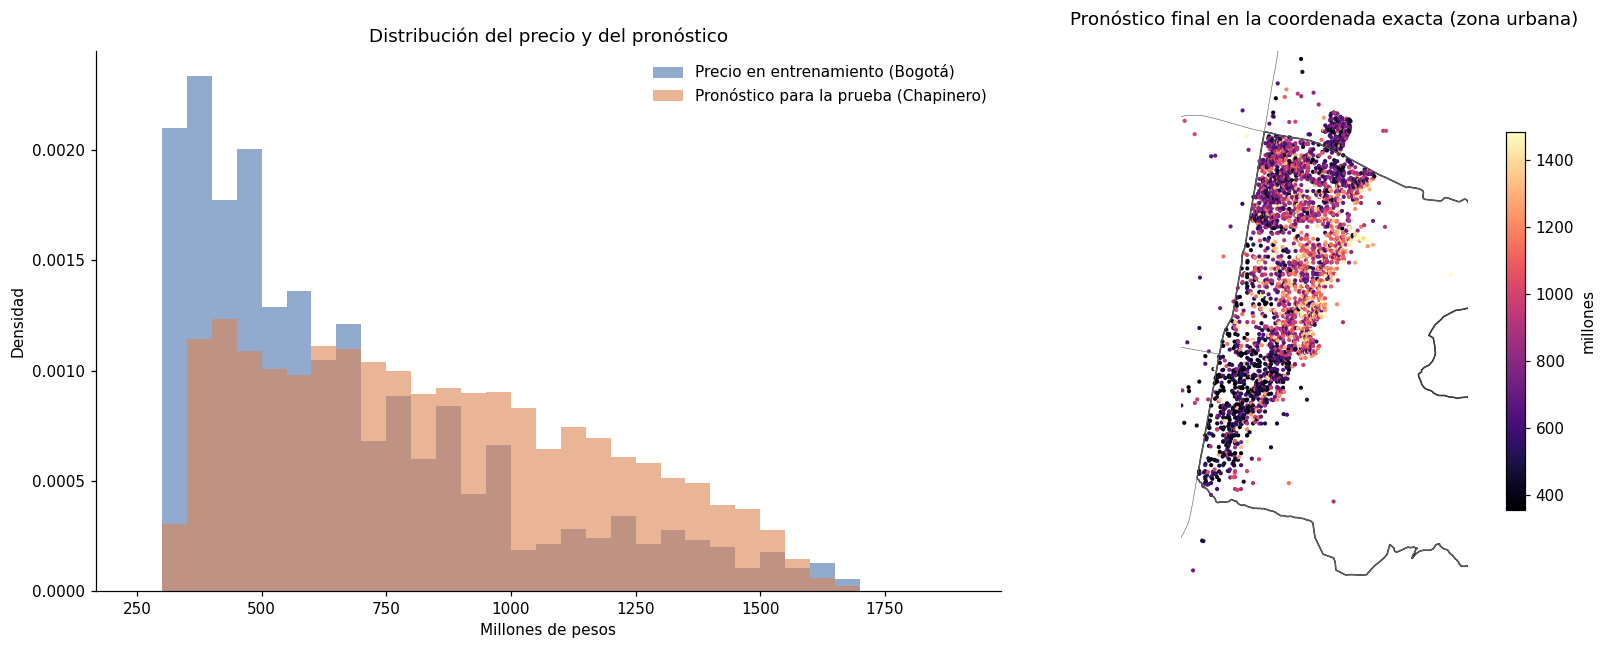

Pronóstico final: mediana 799,5, media 840,5, 17,3 % por encima de 1.200 millones
Tiempo del cuaderno: 0,4 minutos


In [14]:
final = envios["02"]["price"].to_numpy() / 1e6
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.2, 1]})
bins = np.arange(250, 1901, 50)
axes[0].hist(y[idx_tr], bins, density=True, alpha=0.6, color=COLOR_TRAIN, label="Precio en entrenamiento (Bogotá)")
axes[0].hist(final, bins, density=True, alpha=0.6, color=COLOR_TEST, label="Pronóstico para la prueba (Chapinero)")
axes[0].set(xlabel="Millones de pesos", ylabel="Densidad", title="Distribución del precio y del pronóstico")
axes[0].legend(frameon=False)
pr = g.iloc[idx_te][["x", "y"]].assign(pred=final).groupby(["x", "y"], as_index=False)["pred"].mean()
sc = axes[1].scatter(pr["x"], pr["y"], c=pr["pred"], s=3, cmap="magma", vmin=pr["pred"].quantile(.02), vmax=pr["pred"].quantile(.98))
chap.boundary.plot(ax=axes[1], color="black", lw=1)
loc.boundary.plot(ax=axes[1], color="grey", lw=0.3)
b_ = chap.total_bounds
axes[1].set_xlim(b_[0] - 300, b_[0] + 0.55 * (b_[2] - b_[0])); axes[1].set_ylim(b_[1] - 300, b_[3] + 1500)
axes[1].set_axis_off(); plt.colorbar(sc, ax=axes[1], shrink=0.7, label="millones")
axes[1].set_title("Pronóstico final en la coordenada exacta (zona urbana)")
fig.tight_layout()
guardar_figura(fig, "pronostico_final")
plt.show()
print(f"Pronóstico final: mediana {coma(np.median(final))}, media {coma(final.mean())}, "
      f"{coma(100 * np.mean(final > 1200))} % por encima de 1.200 millones")
print(f"Tiempo del cuaderno: {coma((time.time() - t0) / 60)} minutos")

## 7. Resumen

| Paso | Decisión | Evidencia |
|---|---|---|
| Variables | 162 columnas: vivienda, OSM, Earth Engine, entorno adicional, Catastro, texto, coordenadas y puntaje de texto | Catastro bajó Chapinero fuera de 152,8 a 143,8 (cuaderno 03) |
| Algoritmo | LightGBM L2 en niveles, 5 semillas, parada temprana espacial | Gana a las otras familias en las tres validaciones (cuaderno 03) |
| Validación para decidir | Chapinero fuera | Es la más cercana a Kaggle y ordena los tres envíos como la tabla privada |
| Ajuste | ×1,08 alrededor de 654 | Chapinero fuera de 143,8 a 140,8; Kaggle privado de 152,43 a 150,79 |
| Gemelos | 0,3 modelo + 0,7 precio del gemelo en 78 avisos | Regla fija; respaldada a posteriori en clústeres |

Dónde se equivoca este modelo y qué significa para comprar vivienda: cuaderno 04.